# Person Re-ID with a Vision-Language Model
1. Training a ResNet-50 re-ID **teacher** (BoT-style) and uses it to shortlist gallery candidates.
2. Training **Qwen2-VL-2B (LoRA)** as a *same-person verifier*: hard labels vs **distillation from the teacher**.
3. Evaluating Rank-1 / mAP (VLM re-ranks the teacher shortlist), then **token pruning** (random / diversity, independent vs shared-index) at 75 / 50 / 25 % of visual tokens, with latency, memory and decision-flip rate.
4. Comparing with published state-of-the-art numbers and launches a **Gradio demo app**.



In [ ]:
!pip -q install "transformers==4.51.3" "peft==0.15.2" accelerate kagglehub scikit-learn pandas matplotlib "gradio>=5,<6"


In [ ]:
import os, re, json, gc, time, random, glob, shutil
from collections import defaultdict
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm

# ---------------- CONFIG ----------------
SEED = 0
MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'
IMG_W, IMG_H = 224, 448          # 8x16 = 128 visual tokens per image
USE_TEACHER_B = True             # teacher B (all train ids, longer) does the retrieval shortlist; teacher A (70% ids) makes the distillation targets
TEACHER_A_ITERS, TEACHER_B_ITERS = 2500, 4000
N_TRAIN_PAIRS = 3000
EPOCHS, GRAD_ACC, LR = 1, 8, 1e-4
N_QUERIES = 200                  # queries used in the ablation grid (None = all 3368)
SHORTLIST_K = 10
BUDGETS = [0.5, 0.25, 0.75]      # evaluation order: most informative first
PRUNE_METHODS = ['random_indep', 'random_shared', 'div_indep', 'div_shared', 'diff_shared']
RANDOM_SEEDS = [0]
ALPHA_HARD, ALPHA_DISTILL = 1.0, 0.3
SAVE_TEACHER_EVERY, SAVE_STUDENT_STEPS, SAVE_Q = 500, 25, 10
MARKET_ROOT = None
USE_DRIVE = True

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), 'Use Runtime > Change runtime type > GPU'
DEV = 'cuda'
if USE_DRIVE:
    from google.colab import drive; drive.mount('/content/drive'); WORK = '/content/drive/MyDrive/pruneprobe_reid'
else:
    WORK = '/content/pruneprobe_reid'
CK = f'{WORK}/ckpt'; os.makedirs(CK, exist_ok=True)
RUN_ID = f'q{N_QUERIES}_k{SHORTLIST_K}'        # results of different settings never get mixed

# ---- checkpoint helpers (atomic writes so a disconnect can never leave a half-written file) ----
def jload(p):
    try: return json.load(open(p))
    except Exception: return None
def jdump(o, p):
    os.makedirs(os.path.dirname(p), exist_ok=True); t = p + '.tmp'; json.dump(o, open(t, 'w')); os.replace(t, p)
def tsave(o, p): t = p + '.tmp'; torch.save(o, t); os.replace(t, p)
def tload(p):
    if not os.path.exists(p): return None
    try: return torch.load(p, map_location='cpu', weights_only=False)
    except Exception as e: print('unreadable checkpoint, restarting that stage:', p, e); return None
def status():
    print('checkpoint folder:', CK)
    for f in sorted(glob.glob(f'{CK}/**/*', recursive=True)):
        if os.path.isfile(f) and not f.endswith('.tmp'): print(f'  {os.path.relpath(f, CK):70s} {os.path.getsize(f)/1e6:8.1f} MB')
print('work dir', WORK, '|', torch.cuda.get_device_name(0), '| capability', torch.cuda.get_device_capability())

Mounted at /content/drive
work dir /content/drive/MyDrive/pruneprobe_reid | Tesla T4 | capability (7, 5)


## 1. Data: Market-1501

In [ ]:
def find_root(base):
    for r, ds, _ in os.walk(base):
        if 'bounding_box_train' in ds and 'query' in ds and 'bounding_box_test' in ds: return r
    return None
root = MARKET_ROOT
if root is None:
    import kagglehub
    root = find_root(kagglehub.dataset_download('pengcw1/market-1501'))   # if this fails: upload Market-1501 and set MARKET_ROOT
assert root, 'Market-1501 folders not found. Set MARKET_ROOT.'
def parse(p):
    m = re.match(r'(-?\d+)_c(\d)', os.path.basename(p)); return int(m.group(1)), int(m.group(2))
lst = lambda d: sorted(glob.glob(f'{root}/{d}/*.jpg'))
train_p, gal_p, qry_p = lst('bounding_box_train'), lst('bounding_box_test'), lst('query')
train_id = np.array([parse(p)[0] for p in train_p]); gal_id = np.array([parse(p)[0] for p in gal_p]); gal_cam = np.array([parse(p)[1] for p in gal_p])
qry_id = np.array([parse(p)[0] for p in qry_p]); qry_cam = np.array([parse(p)[1] for p in qry_p])
ids = sorted(set(train_id.tolist())); random.Random(SEED).shuffle(ids); cut = int(0.7 * len(ids))
T_IDS, S_IDS, ALL_IDS = set(ids[:cut]), set(ids[cut:]), set(ids)
student_items = [(p, i) for p, i in zip(train_p, train_id) if i in S_IDS]
print(len(train_p), 'train |', len(gal_p), 'gallery |', len(qry_p), 'queries |', len(T_IDS), 'teacher-A ids /', len(S_IDS), 'student ids')

100%|██████████| 146M/146M [00:02<00:00, 72.1MB/s]

Extracting files...


12936 train | 19732 gallery | 3368 queries | 525 teacher-A ids / 226 student ids


## 2. Teachers (resumable): A = 70% of train ids (distillation targets), B = all train ids (retrieval shortlist)

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = T.Compose([T.Resize((256, 128)), T.RandomHorizontalFlip(), T.Pad(10), T.RandomCrop((256, 128)), T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=0.5)])
tf_test = T.Compose([T.Resize((256, 128)), T.ToTensor(), T.Normalize(MEAN, STD)])
class ImgDS(Dataset):
    def __init__(s, items, tf): s.items, s.tf = items, tf
    def __len__(s): return len(s.items)
    def __getitem__(s, i): p, y = s.items[i]; return s.tf(Image.open(p).convert('RGB')), y

class ReIDNet(nn.Module):
    def __init__(s, n_cls, pretrained=True):
        super().__init__(); r = torchvision.models.resnet50(weights='IMAGENET1K_V2' if pretrained else None)
        r.layer4[0].conv2.stride = (1, 1); r.layer4[0].downsample[0].stride = (1, 1)
        s.backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
        s.pool = nn.AdaptiveAvgPool2d(1); s.bn = nn.BatchNorm1d(2048); s.bn.bias.requires_grad_(False); s.cls = nn.Linear(2048, n_cls, bias=False)
    def forward(s, x):
        f = s.pool(s.backbone(x)).flatten(1); fb = s.bn(f); return (f, s.cls(fb)) if s.training else fb

def pk_batches(items, P=16, K=4, n_iters=1000, seed=0):
    rng = random.Random(seed); by = defaultdict(list)
    for i, (_, y) in enumerate(items): by[y].append(i)
    pids = list(by)
    for _ in range(n_iters):
        b = []
        for pid in rng.sample(pids, P): b += rng.choices(by[pid], k=K) if len(by[pid]) < K else rng.sample(by[pid], K)
        yield b

def load_teacher(tag):
    sd = tload(f'{CK}/teacher_{tag}.pt'); net = ReIDNet(sd['cls.weight'].shape[0], pretrained=False); net.load_state_dict(sd); return net.to(DEV)

def train_teacher(tag, id_set, iters):
    final, state_path = f'{CK}/teacher_{tag}.pt', f'{CK}/teacher_{tag}_state.pt'
    if os.path.exists(final): print(f'teacher {tag}: done'); return load_teacher(tag)
    lab = {p: i for i, p in enumerate(sorted(id_set))}; items = [(p, lab[y]) for p, y in zip(train_p, train_id) if y in id_set]
    net = ReIDNet(len(lab)).to(DEV); ds = ImgDS(items, tf_train)
    opt = torch.optim.Adam([p for p in net.parameters() if p.requires_grad], lr=3.5e-4, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / 200) * 0.5 * (1 + np.cos(np.pi * i / iters)))
    scaler = torch.amp.GradScaler('cuda'); start = 0; st = tload(state_path)
    if st:
        net.load_state_dict(st['net']); opt.load_state_dict(st['opt']); sched.load_state_dict(st['sched']); scaler.load_state_dict(st['scaler']); start = st['it']
        print(f'teacher {tag}: RESUMING at iteration {start}/{iters}')
    batches = list(pk_batches(items, n_iters=iters, seed=SEED + (0 if tag == 'A' else 1)))[start:]
    net.train(); dl = DataLoader(ds, batch_sampler=batches, num_workers=2)
    for k, (x, y) in enumerate(tqdm(dl, total=len(batches), desc=f'teacher {tag}')):
        it = start + k; x, y = x.to(DEV), y.to(DEV)
        with torch.autocast('cuda', dtype=torch.float16): f, logits = net(x)
        f = f.float(); d = torch.cdist(f, f); same = (y[:, None] == y[None]).float()
        loss = F.cross_entropy(logits.float(), y, label_smoothing=0.1) + F.relu((d * same).max(1)[0] - (d + 1e5 * same).min(1)[0] + 0.3).mean()
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        if it % 250 == 0: print(it, round(loss.item(), 3))
        if (it + 1) % SAVE_TEACHER_EVERY == 0 and it + 1 < iters:
            tsave(dict(it=it + 1, net=net.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict()), state_path)
    tsave(net.state_dict(), final); return net.eval()

# reuse the teacher from the first version of this notebook if it exists (same seed/split = same teacher A)
if os.path.exists(f'{WORK}/teacher.pt') and not os.path.exists(f'{CK}/teacher_A.pt'): shutil.copy(f'{WORK}/teacher.pt', f'{CK}/teacher_A.pt'); print('reused old teacher.pt as teacher A')
netA = train_teacher('A', T_IDS, TEACHER_A_ITERS)
netB = train_teacher('B', ALL_IDS, TEACHER_B_ITERS) if USE_TEACHER_B else netA

@torch.no_grad()
def embed(net, paths, bs=128):
    net.eval(); out = []
    for x, _ in tqdm(DataLoader(ImgDS([(p, 0) for p in paths], tf_test), batch_size=bs, num_workers=2), desc='embed'):
        with torch.autocast('cuda', dtype=torch.float16): f = net(x.to(DEV))
        out.append(F.normalize(f.float(), dim=1).cpu())
    return torch.cat(out)
def embed_cached(net, paths, tag):
    p = f'{CK}/emb_{tag}.pt'; e = tload(p)
    if e is not None and len(e) == len(paths): return e
    e = embed(net, paths); tsave(e, p); return e

RET = 'B' if USE_TEACHER_B else 'A'
G_emb = embed_cached(netB, gal_p, f'G_{RET}'); Q_emb = embed_cached(netB, qry_p, f'Q_{RET}')
S_emb = embed_cached(netA, [p for p, _ in student_items], 'S_A')
print('embeddings', tuple(G_emb.shape), tuple(Q_emb.shape), tuple(S_emb.shape))

reused old teacher.pt as teacher A
teacher A: done
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 43.6MB/s]


teacher B:   0%|          | 0/4000 [00:00<?, ?it/s]

/tmp/ipykernel_2487/1253864262.py:48: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


0 8.641
250 5.341
500 2.073
750 1.529
1000 1.394
1250 1.371
1500 1.273
1750 1.286
2000 1.236
2250 1.169
2500 1.104
2750 1.109
3000 1.117
3250 1.107
3500 1.08
3750 1.086


embed:   0%|          | 0/155 [00:00<?, ?it/s]

embed:   0%|          | 0/27 [00:00<?, ?it/s]

embed:   0%|          | 0/30 [00:00<?, ?it/s]

embeddings (19732, 2048) (3368, 2048) (3822, 2048)


## 3. Ranking protocol + teacher-only baseline (standard Market-1501 Rank-1 / mAP)

In [ ]:
def rank_stats(matches):
    npos = matches.sum()
    if npos == 0: return None
    hits = np.where(matches)[0]; return float(matches[0]), float(np.mean((np.arange(len(hits)) + 1) / (hits + 1)))

def prep_query(qi):
    valid = (gal_id != -1) & ~((gal_id == qry_id[qi]) & (gal_cam == qry_cam[qi]))      # drop junk and same-id-same-camera
    sims = (G_emb @ Q_emb[qi]).numpy(); sims[~valid] = -9
    order = np.argsort(-sims); order = order[valid[order]]; return order, (gal_id == qry_id[qi])
PREP = {}
def get_prep(qi):
    if qi not in PREP: PREP[qi] = prep_query(qi)
    return PREP[qi]

ALL_Q = [qi for qi in range(len(qry_p)) if ((gal_id == qry_id[qi]) & ~((gal_id == qry_id[qi]) & (gal_cam == qry_cam[qi]))).any()]
rng = np.random.RandomState(SEED)
Q_SUB = [int(q) for q in (rng.choice(ALL_Q, N_QUERIES, replace=False) if (N_QUERIES and N_QUERIES < len(ALL_Q)) else ALL_Q)]

def summarize(r1, ap, boot=1000):
    r1, ap = np.array(r1), np.array(ap); b = np.random.RandomState(0).randint(0, len(ap), (boot, len(ap))); ci = lambda a: float(1.96 * a[b].mean(1).std())
    return dict(R1=float(100 * r1.mean()), R1_ci=100 * ci(r1), mAP=float(100 * ap.mean()), mAP_ci=100 * ci(ap))
def teacher_only(qs):
    r = [rank_stats(get_prep(q)[1][get_prep(q)[0]]) for q in qs]
    return {**summarize([a for a, _ in r], [b for _, b in r]), 'r1_list': [a for a, _ in r], 'ap_list': [b for _, b in r]}

results, results_full, LOGITS = {}, {}, {}
results['Teacher ResNet-50 (retrieval backbone, no VLM)'] = {**teacher_only(Q_SUB), 'sec_per_pair': None, 'peak_gb': None}
print({k: round(v, 2) for k, v in results['Teacher ResNet-50 (retrieval backbone, no VLM)'].items() if k in ('R1', 'mAP')}, f'on {len(Q_SUB)} queries')

{'R1': 92.0, 'mAP': 76.52} on 200 queries


## 4. Qwen2-VL verifier with token pruning (fp16 on T4, cached vision features)

In [ ]:

def fps(x, k):
    """Greedy farthest-point (diversity) selection on L2-normalised token features x (n,d). DivPrune-style."""
    n = x.shape[0]; k = min(k, n)
    c = F.normalize(x.mean(0, keepdim=True), dim=-1)
    sel = [int((1 - x @ c.T).squeeze(1).argmax())]
    mind = 1 - x @ x[sel[0]]
    for _ in range(k - 1):
        j = int(mind.argmax()); sel.append(j)
        mind = torch.minimum(mind, 1 - x @ x[j])
    return torch.tensor(sorted(sel), device=x.device)

def select_tokens(method, fA, fB, budget, seed=0):
    """Return indices (into the N visual tokens of each image) to KEEP for image A and image B."""
    N = fA.shape[0]; k = max(1, int(round(budget * N)))
    allidx = torch.arange(N, device=fA.device)
    if method == 'dense' or k >= N:
        return allidx, allidx
    a, b = F.normalize(fA.float(), dim=-1), F.normalize(fB.float(), dim=-1)
    g = torch.Generator().manual_seed(int(seed))
    if method == 'random_indep':
        ia = torch.randperm(N, generator=g)[:k]; ib = torch.randperm(N, generator=g)[:k]
        return ia.sort().values.to(fA.device), ib.sort().values.to(fA.device)
    if method == 'random_shared':
        i = torch.randperm(N, generator=g)[:k].sort().values.to(fA.device); return i, i
    if method == 'div_indep':
        return fps(a, k), fps(b, k)
    if method == 'div_shared':      # one common set of positions chosen from the pair's joint features
        i = fps(torch.cat([a, b], 1) / 2 ** 0.5, k); return i, i
    if method == 'diff_shared':     # keep positions where the two images differ most (diagnostic ablation)
        i = (1 - (a * b).sum(-1)).topk(k).indices.sort().values; return i, i
    raise ValueError(method)


In [ ]:
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict, PeftModel

DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16   # T4 (capability 7.5): fp16. bf16 is emulated there and ~10x slower.
processor = AutoProcessor.from_pretrained(MODEL_ID)
YES = processor.tokenizer.encode('Yes', add_special_tokens=False)[0]; NO = processor.tokenizer.encode('No', add_special_tokens=False)[0]
MSGS = [{'role': 'user', 'content': [
    {'type': 'text', 'text': 'Image 1 shows a pedestrian.'}, {'type': 'image'},
    {'type': 'text', 'text': 'Image 2 shows a pedestrian.'}, {'type': 'image'},
    {'type': 'text', 'text': 'Are these two images of the same person? Answer Yes or No.'}]}]
PROMPT = processor.apply_chat_template(MSGS, add_generation_prompt=True)
_d = Image.new('RGB', (IMG_W, IMG_H)); _t = processor(text=[PROMPT], images=[_d, _d], return_tensors='pt')
TPL = dict(ids=_t['input_ids'].to(DEV), grid=_t['image_grid_thw'].to(DEV), am=_t['attention_mask'].to(DEV), pos=None)   # identical for every pair
print('tokens per pair:', int((TPL['ids'] == processor.tokenizer.convert_tokens_to_ids('<|image_pad|>')).sum()), '| dtype', DTYPE)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

tokens per pair: 256 | dtype torch.float16


In [ ]:
VIS = {}            # image path -> (128, H) visual tokens (frozen vision tower => identical for every LoRA/model variant)
VIS_MAX = 3000
unwrap = lambda m: m.get_base_model() if hasattr(m, 'get_base_model') else m
def sync(): torch.cuda.synchronize(); return time.time()
autocast = lambda: torch.autocast('cuda', dtype=DTYPE, enabled=(DTYPE != torch.float32))

def encode_pil(model, img):
    inner = unwrap(model)
    px = processor.image_processor(images=[img.convert('RGB').resize((IMG_W, IMG_H))], return_tensors='pt')
    with torch.no_grad():
        vdt = next(inner.visual.parameters()).dtype
        return inner.visual(px['pixel_values'].to(DEV, vdt), grid_thw=px['image_grid_thw'].to(DEV))

def encode_image(model, path):
    f = VIS.get(path)
    if f is None:
        f = encode_pil(model, Image.open(path))
        if len(VIS) >= VIS_MAX: VIS.pop(next(iter(VIS)))
        VIS[path] = f
    return f

def logit_from_feats(model, fA, fB, method='dense', budget=1.0, seed=0):
    """logit(Yes)-logit(No) for 'same person?'. Visual tokens are pruned AFTER the vision encoder; kept tokens keep their original M-RoPE positions."""
    inner = unwrap(model); ids = TPL['ids']
    if TPL['pos'] is None: TPL['pos'] = inner.get_rope_index(ids, TPL['grid'], None, TPL['am'])[0]
    emb = inner.model.embed_tokens(ids); mask = (ids == inner.config.image_token_id)
    emb = emb.masked_scatter(mask.unsqueeze(-1).expand_as(emb), torch.cat([fA, fB]).to(emb.dtype))
    N = fA.shape[0]; ka, kb = select_tokens(method, fA, fB, budget, seed)
    ipos = mask[0].nonzero().squeeze(1)
    dA = torch.ones(N, dtype=torch.bool, device=ids.device); dA[ka] = False
    dB = torch.ones(N, dtype=torch.bool, device=ids.device); dB[kb] = False
    keep = torch.ones(ids.shape[1], dtype=torch.bool, device=ids.device); keep[torch.cat([ipos[:N][dA], ipos[N:][dB]])] = False
    emb, pos = emb[:, keep], TPL['pos'][:, :, keep]
    out = model(inputs_embeds=emb, position_ids=pos, attention_mask=torch.ones(1, emb.shape[1], dtype=torch.long, device=ids.device), use_cache=False)
    lg = out.logits[0, -1].float(); return lg[YES] - lg[NO]


In [ ]:
def load_base():
    global DTYPE
    for _ in range(2):
        gc.collect(); torch.cuda.empty_cache()
        m = Qwen2VLForConditionalGeneration.from_pretrained(MODEL_ID, torch_dtype=DTYPE, attn_implementation='sdpa').to(DEV); m.config.use_cache = False
        if DTYPE == torch.float32: return m
        with torch.no_grad(), autocast(): z = logit_from_feats(m, encode_pil(m, Image.open(gal_p[0])), encode_pil(m, Image.open(gal_p[1])))
        if torch.isfinite(z): return m
        print('non-finite output in', DTYPE, '-> falling back to float32'); DTYPE = torch.float32; VIS.clear(); TPL['pos'] = None; del m
    return m

def get_student(name):
    """Load a trained LoRA student from the checkpoint folder."""
    m = PeftModel.from_pretrained(load_base(), f'{CK}/lora_{name}'); return m.eval()

def measure_vis_ms(model):
    p = f'{CK}/vis_ms.json'; j = jload(p)
    if j: return j['ms']
    paths = gal_p[100:130]; encode_pil(model, Image.open(paths[0])); ts = []
    for q in paths:
        t0 = sync(); encode_pil(model, Image.open(q)); ts.append(sync() - t0)
    jdump({'ms': 1000 * float(np.mean(ts))}, p); return 1000 * float(np.mean(ts))

## 5. Evaluation with progress checkpoints (teacher shortlist -> VLM re-rank -> Rank-1 / mAP over the full gallery)

In [ ]:
safe = lambda s: re.sub(r'[^A-Za-z0-9_.-]+', '_', s)

def score_fn(model, qpath, gpath, method, budget, seed):
    z = logit_from_feats(model, encode_image(model, qpath), encode_image(model, gpath), method, budget, seed); return float(z)

@torch.no_grad()
def eval_vlm(model, name, method='dense', budget=1.0, rseed=0, qs=None, run_id=None, store=None):
    qs = Q_SUB if qs is None else qs; run_id = run_id or RUN_ID; store = results if store is None else store
    key = f'{name} | {method} | {budget}' + (f' | seed{rseed}' if method.startswith('random') else '')
    fpath = f'{CK}/{run_id}/eval_{safe(key)}.json'; st = jload(fpath)
    if st and st.get('final'):
        store[key] = st['final']; LOGITS[key] = {(a, b): z for a, b, z in st['Z']}; print('done already:', key); return key
    st = st or dict(n=0, r1=[], ap=[], t=[], tok=[], Z=[])
    if st['n']: print(f'RESUMING {key} at query {st["n"]}/{len(qs)}')
    model.eval(); torch.cuda.reset_peak_memory_stats()
    for idx in tqdm(range(st['n'], len(qs)), initial=st['n'], total=len(qs), desc=key):
        qi = int(qs[idx]); order, match = get_prep(qi); cand = order[:SHORTLIST_K]; zs = []
        for j, g in enumerate(cand):
            with autocast():
                t0 = sync(); z = score_fn(model, qry_p[qi], gal_p[g], method, budget, rseed * 1_000_003 + qi * 101 + j); st['t'].append(sync() - t0)
            zs.append(z); st['Z'].append([qi, int(g), z])
        st['tok'].append(256 if method == 'dense' or budget >= 1 else 2 * max(1, int(round(budget * 128))))
        new = np.concatenate([cand[np.argsort(-np.array(zs))], order[SHORTLIST_K:]]); a, b = rank_stats(match[new]); st['r1'].append(a); st['ap'].append(b)
        if (idx + 1) % SAVE_Q == 0: st['n'] = idx + 1; jdump(st, fpath)
    st['n'] = len(qs)
    fin = {**summarize(st['r1'], st['ap']), 'llm_sec_per_pair': float(np.mean(st['t'][3:])), 'peak_gb': torch.cuda.max_memory_allocated() / 1e9,
           'tokens_per_pair': float(np.mean(st['tok'])), 'model': name, 'method': method, 'budget': float(budget), 'r1_list': st['r1'], 'ap_list': st['ap']}
    st['final'] = fin; jdump(st, fpath); store[key] = fin; LOGITS[key] = {(a, b): z for a, b, z in st['Z']}; return key

def add_flip(key, dense_key):
    zs, zd = LOGITS[key], LOGITS[dense_key]; ks = [k for k in zs if k in zd]
    results[key]['flip_vs_dense'] = float(np.mean([(zs[k] > 0) != (zd[k] > 0) for k in ks]))
    results[key]['speedup_llm'] = results[dense_key]['llm_sec_per_pair'] / results[key]['llm_sec_per_pair']

def eta(sec_per_pair, n_cfg, qs=None):
    n = n_cfg * len(Q_SUB if qs is None else qs) * SHORTLIST_K; print(f'~{sec_per_pair*1000:.0f} ms/pair -> {n} pairs ~ {n*sec_per_pair/60:.0f} min for {n_cfg} configs')

### Zero-shot Qwen2-VL (before training)

In [ ]:
model = load_base(); VIS_MS = measure_vis_ms(model); print(f'vision encoder: {VIS_MS:.0f} ms per image')
k0 = eval_vlm(model, 'Qwen zero-shot'); print({m: round(v, 3) for m, v in results[k0].items() if m in ('R1', 'mAP', 'llm_sec_per_pair', 'peak_gb')})
eta(results[k0]['llm_sec_per_pair'], 1 + 1 + 1 + len(PRUNE_METHODS) * len(BUDGETS))
del model; gc.collect(); torch.cuda.empty_cache()

config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.99G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/429M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

vision encoder: 65 ms per image


Qwen zero-shot | dense | 1.0:   0%|          | 0/200 [00:00<?, ?it/s]

{'R1': 81.5, 'mAP': 72.538, 'llm_sec_per_pair': 0.146, 'peak_gb': 5.648}
~146 ms/pair -> 36000 pairs ~ 87 min for 18 configs


## 6. Student training pairs (teacher-A-unseen identities) with calibrated teacher soft targets

In [ ]:
from sklearn.linear_model import LogisticRegression
S_y = np.array([y for _, y in student_items]); S_cam = np.array([parse(p)[1] for p, _ in student_items])
sim = (S_emb @ S_emb.T).numpy(); np.fill_diagonal(sim, -9)
byid = defaultdict(list)
for i, y in enumerate(S_y): byid[y].append(i)
rng = random.Random(SEED); raw = []; guard = 0
while len(raw) < N_TRAIN_PAIRS and guard < 50 * N_TRAIN_PAIRS:
    guard += 1
    if len(raw) % 2 == 0:                                            # positive (prefer a different camera)
        y = rng.choice(list(byid)); a = rng.choice(byid[y]); alt = [j for j in byid[y] if j != a and S_cam[j] != S_cam[a]] or [j for j in byid[y] if j != a]
        if alt: raw.append((a, rng.choice(alt), 1))
    else:                                                             # negative: half hard (teacher-similar), half random
        a = rng.randrange(len(S_y))
        b = int(rng.choice([j for j in np.argsort(-sim[a])[:30] if S_y[j] != S_y[a]] or [rng.randrange(len(S_y))])) if rng.random() < 0.5 else rng.randrange(len(S_y))
        if S_y[a] != S_y[b]: raw.append((a, b, 0))
cs = np.array([[sim[a, b]] for a, b, _ in raw]); ys = np.array([l for *_, l in raw])
tp = LogisticRegression(C=1e3).fit(cs, ys).predict_proba(cs)[:, 1]          # teacher cosine -> P(same person)
train_pairs = [(student_items[a][0], student_items[b][0], l, float(p)) for (a, b, l), p in zip(raw, tp)]
EP_ORDERS = [random.Random(SEED + e).sample(range(len(train_pairs)), len(train_pairs)) for e in range(EPOCHS)]   # deterministic => exact resume
print(len(train_pairs), 'pairs | teacher accuracy on them:', ((tp > 0.5) == ys).mean().round(3))

3000 pairs | teacher accuracy on them: 0.776


## 7. LoRA training (resumable): hard labels vs distillation from the teacher

In [ ]:
def train_student(name, alpha):
    final = f'{CK}/lora_{name}'
    if os.path.exists(f'{final}/adapter_config.json'): print(f'student {name}: training already done'); return
    model = get_peft_model(load_base(), LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj'], task_type='CAUSAL_LM'))
    for p in model.parameters():
        if p.requires_grad: p.data = p.data.float()
    params = [p for p in model.parameters() if p.requires_grad]; opt = torch.optim.AdamW(params, lr=LR)
    scaler = torch.amp.GradScaler('cuda', enabled=(DTYPE == torch.float16)); total = EPOCHS * len(train_pairs)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: max(0.05, 1 - s / max(1, total // GRAD_ACC)))
    spath = f'{CK}/student_{name}_state.pt'; st = tload(spath); done_pairs = 0; step = 0
    if st:
        set_peft_model_state_dict(model, st['lora']); opt.load_state_dict(st['opt']); sched.load_state_dict(st['sched']); scaler.load_state_dict(st['scaler'])
        done_pairs, step = st['pairs_done'], st['step']; print(f'student {name}: RESUMING at pair {done_pairs}/{total}')
    model.train(); run = []
    for flat in tqdm(range(done_pairs, total), initial=done_pairs, total=total, desc=name):
        ep, i = divmod(flat, len(train_pairs)); a, b, l, p = train_pairs[EP_ORDERS[ep][i]]
        if random.Random(SEED * 7919 + flat).random() < 0.5: a, b = b, a
        with autocast(): z = logit_from_feats(model, encode_image(model, a), encode_image(model, b))
        bce = F.binary_cross_entropy_with_logits
        loss = (alpha * bce(z, torch.tensor(float(l), device=DEV)) + (1 - alpha) * bce(z, torch.tensor(p, device=DEV))) / GRAD_ACC
        scaler.scale(loss).backward(); run.append(loss.item() * GRAD_ACC)
        if (flat + 1) % GRAD_ACC == 0:
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0); scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); step += 1
            if step % 25 == 0: print(f'step {step} loss {np.mean(run[-200:]):.4f}')
            if step % SAVE_STUDENT_STEPS == 0 and flat + 1 < total:
                tsave(dict(lora={k: v.cpu() for k, v in get_peft_model_state_dict(model).items()}, opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(), pairs_done=flat + 1, step=step), spath)
    model.save_pretrained(final); print('saved', final)
    del model, opt; gc.collect(); torch.cuda.empty_cache()

for nm, al in [('hard', ALPHA_HARD), ('distilled', ALPHA_DISTILL)]:
    train_student(nm, al)
    m = get_student(nm); VIS_MS = measure_vis_ms(m); key = eval_vlm(m, f'Qwen LoRA {nm}'); print({a: round(v, 3) for a, v in results[key].items() if a in ('R1', 'mAP', 'llm_sec_per_pair')})
    if nm == 'distilled': student, DENSE = m, key
    else: del m; gc.collect(); torch.cuda.empty_cache()

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

hard:   0%|          | 0/3000 [00:00<?, ?it/s]

step 25 loss 0.5177
step 50 loss 0.5787
step 75 loss 0.4887
step 100 loss 0.4980
step 125 loss 0.4224
step 150 loss 0.4418
step 175 loss 0.4011
step 200 loss 0.5327
step 225 loss 0.4481
step 250 loss 0.3380
step 275 loss 0.3712
step 300 loss 0.4257
step 325 loss 0.4293
step 350 loss 0.4045
step 375 loss 0.3419
saved /content/drive/MyDrive/pruneprobe_reid/ckpt/lora_hard


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Qwen LoRA hard | dense | 1.0:   0%|          | 0/200 [00:00<?, ?it/s]

{'R1': 82.5, 'mAP': 74.177, 'llm_sec_per_pair': 0.157}


... (2 outputs left out)

step 25 loss 0.5715
step 50 loss 0.5235
step 75 loss 0.5653
step 100 loss 0.5422
step 125 loss 0.5093
step 150 loss 0.5006
step 175 loss 0.4963
step 200 loss 0.4990
step 225 loss 0.5464
step 250 loss 0.4910
step 275 loss 0.5024
step 300 loss 0.4830
step 325 loss 0.4808
step 350 loss 0.4880
step 375 loss 0.4983
saved /content/drive/MyDrive/pruneprobe_reid/ckpt/lora_distilled


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Qwen LoRA distilled | dense | 1.0:   0%|          | 0/200 [00:00<?, ?it/s]

{'R1': 83.0, 'mAP': 74.192, 'llm_sec_per_pair': 0.156}


## 8. Pruning grid on the distilled model (independent vs shared-index at matched budgets), resumable

In [ ]:
for b in BUDGETS:
    for method in PRUNE_METHODS:
        for rs_ in (RANDOM_SEEDS if method.startswith('random') else [0]):
            k = eval_vlm(student, 'Qwen LoRA distilled', method, b, rs_); add_flip(k, DENSE)
            print(k, {m: round(v, 3) for m, v in results[k].items() if m in ('R1', 'mAP', 'llm_sec_per_pair', 'flip_vs_dense', 'speedup_llm')})

Qwen LoRA distilled | random_indep | 0.5 | seed0:   0%|          | 0/200 [00:00<?, ?it/s]

Qwen LoRA distilled | random_indep | 0.5 | seed0 {'R1': 82.0, 'mAP': 73.294, 'llm_sec_per_pair': 0.079, 'flip_vs_dense': 0.092, 'speedup_llm': 1.975}


Qwen LoRA distilled | random_shared | 0.5 | seed0:   0%|          | 0/200 [00:00<?, ?it/s]

Qwen LoRA distilled | random_shared | 0.5 | seed0 {'R1': 83.5, 'mAP': 73.051, 'llm_sec_per_pair': 0.078, 'flip_vs_dense': 0.094, 'speedup_llm': 2.002}


Qwen LoRA distilled | div_indep | 0.5:   0%|          | 0/200 [00:00<?, ?it/s]

Qwen LoRA distilled | div_indep | 0.5 {'R1': 83.5, 'mAP': 73.484, 'llm_sec_per_pair': 0.099, 'flip_vs_dense': 0.115, 'speedup_llm': 1.577}


... (20 outputs left out)

Qwen LoRA distilled | div_shared | 0.75:   0%|          | 0/200 [00:00<?, ?it/s]

Qwen LoRA distilled | div_shared | 0.75 {'R1': 84.0, 'mAP': 74.102, 'llm_sec_per_pair': 0.092, 'flip_vs_dense': 0.043, 'speedup_llm': 1.696}


Qwen LoRA distilled | diff_shared | 0.75:   0%|          | 0/200 [00:00<?, ?it/s]

Qwen LoRA distilled | diff_shared | 0.75 {'R1': 83.0, 'mAP': 73.987, 'llm_sec_per_pair': 0.077, 'flip_vs_dense': 0.04, 'speedup_llm': 2.036}


## 9. Headline run on ALL 3368 queries (optional, resumable; run last)

Set `RUN_FINAL = True` when you have GPU time. It evaluates the dense distilled model and the 50%-token shared-diversity variant on the full query set.

In [ ]:
RUN_FINAL = False
FINAL_CONFIGS = [('dense', 1.0), ('div_shared', 0.5)]
if RUN_FINAL:
    sp = results[DENSE]['llm_sec_per_pair']; eta(sp, len(FINAL_CONFIGS), ALL_Q)
    results_full['Teacher ResNet-50 (retrieval backbone, no VLM)'] = {**teacher_only(ALL_Q), 'sec_per_pair': None, 'peak_gb': None}
    for meth, b in FINAL_CONFIGS: eval_vlm(student, 'Qwen LoRA distilled', meth, b, qs=ALL_Q, run_id='full', store=results_full)
    print({k: (round(v['R1'], 1), round(v['mAP'], 1)) for k, v in results_full.items()})

## 10. Results table, paired significance, comparison with state of the art

                                                   Rank-1 (±95% CI) mAP (±95% CI) dmAP vs dense (paired 95% CI)  llm_sec_per_pair  total_ms_per_pair  tokens_per_pair  peak_gb  speedup_llm  flip_vs_dense
Teacher ResNet-50 (retrieval backbone, no VLM)           92.0 ± 3.7    76.5 ± 3.5                                             NaN                NaN              NaN      NaN          NaN            NaN
Qwen zero-shot | dense | 1.0                             81.5 ± 5.3    72.5 ± 3.5                    -1.7 ± 1.2             0.146            276.125            256.0    5.648          NaN            NaN
Qwen LoRA hard | dense | 1.0                             82.5 ± 5.3    74.2 ± 3.5                    -0.0 ± 0.5             0.157            287.158            256.0    6.043          NaN            NaN
Qwen LoRA distilled | dense | 1.0                        83.0 ± 5.0    74.2 ± 3.5                    +0.0 ± 0.0             0.156            286.832            256.0    6.043          NaN 

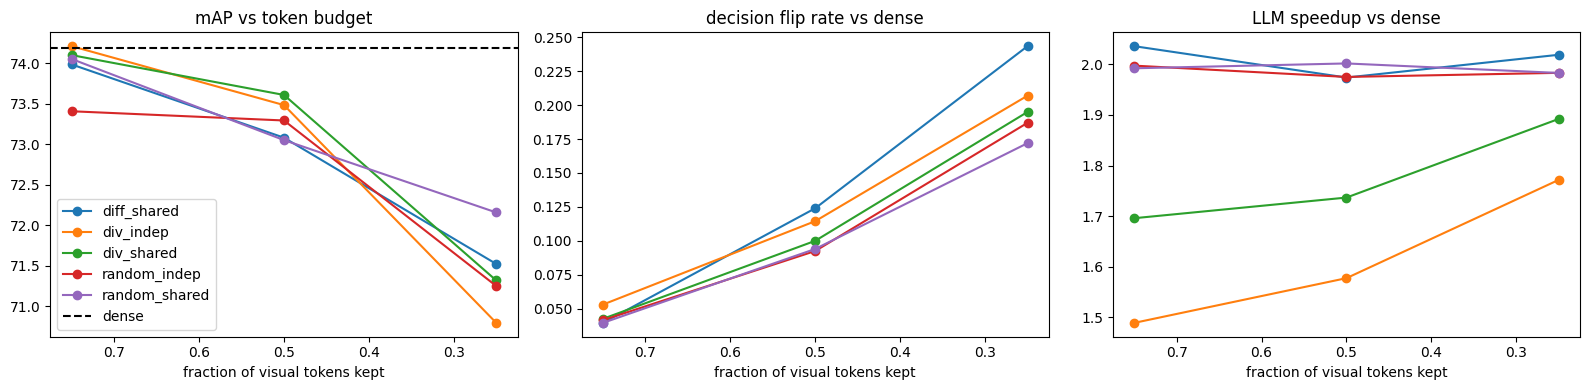

                                                     Method   mAP  Rank1                              Queries                           Source
                                 SOLIDER (Swin), supervised 93.90  96.90        all 3368 (published protocol) survey arXiv 2509.22690, Table 2
                      CLIP-ReID (ViT-B/16 CLIP), supervised 90.50  95.40        all 3368 (published protocol) survey arXiv 2509.22690, Table 2
ChatReID (Qwen2-VL-2B, ICCV 2025), trained on many datasets 96.40  97.20        all 3368 (published protocol)                 arXiv 2502.19958
  STFER (arXiv Apr 2026), cross-domain (trained on AT-USTC) 90.02  93.79        all 3368 (published protocol)                 arXiv 2604.15090
       OURS: Teacher ResNet-50 (retrieval backbone, no VLM) 76.50  92.00 200 (subset, teacher shortlist K=10)                    this notebook
                    OURS: Qwen LoRA distilled | dense | 1.0 74.20  83.00 200 (subset, teacher shortlist K=10)                    this notebook

In [ ]:
def paired_ci(store, key, base, metric='ap_list', boot=2000):
    d = np.array(store[key][metric]) - np.array(store[base][metric]); b = np.random.RandomState(1).randint(0, len(d), (boot, len(d)))
    m = 100 * d.mean(); h = 100 * 1.96 * d[b].mean(1).std(); return f'{m:+.1f} ± {h:.1f}'

df = pd.DataFrame(results).T
for c in ['budget', 'R1', 'mAP', 'R1_ci', 'mAP_ci', 'llm_sec_per_pair', 'peak_gb', 'tokens_per_pair', 'flip_vs_dense', 'speedup_llm']:
    if c in df: df[c] = pd.to_numeric(df[c], errors='coerce')
df['Rank-1 (±95% CI)'] = df.apply(lambda r: f"{r.R1:.1f} ± {r.R1_ci:.1f}", axis=1); df['mAP (±95% CI)'] = df.apply(lambda r: f"{r.mAP:.1f} ± {r.mAP_ci:.1f}", axis=1)
VMS = jload(f'{CK}/vis_ms.json')['ms'] if jload(f'{CK}/vis_ms.json') else float('nan')
df['total_ms_per_pair'] = df.llm_sec_per_pair * 1000 + 2 * VMS          # LLM prefill + 2 vision-encoder passes (pruning only shrinks the LLM part)
if 'Qwen LoRA distilled | dense | 1.0' in results:
    df['dmAP vs dense (paired 95% CI)'] = [paired_ci(results, k, 'Qwen LoRA distilled | dense | 1.0') if k.startswith('Qwen') and 'ap_list' in results[k] else '' for k in df.index]
cols = ['Rank-1 (±95% CI)', 'mAP (±95% CI)', 'dmAP vs dense (paired 95% CI)', 'llm_sec_per_pair', 'total_ms_per_pair', 'tokens_per_pair', 'peak_gb', 'speedup_llm', 'flip_vs_dense']
show = df[[c for c in cols if c in df]].round(3); print(show.to_string()); show.to_csv(f'{WORK}/results_ablation_{RUN_ID}.csv')

import matplotlib.pyplot as plt
g = df[df.model == 'Qwen LoRA distilled'].dropna(subset=['budget']); fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for m, d in g[g.method != 'dense'].groupby('method'):
    d = d.groupby('budget').mean(numeric_only=True).sort_index(ascending=False)
    ax[0].plot(d.index, d.mAP, marker='o', label=m); ax[1].plot(d.index, d.flip_vs_dense, marker='o', label=m); ax[2].plot(d.index, d.speedup_llm, marker='o', label=m)
if (g.method == 'dense').any(): ax[0].axhline(g[g.method == 'dense'].iloc[0].mAP, ls='--', c='k', label='dense')
for a, t in zip(ax, ['mAP vs token budget', 'decision flip rate vs dense', 'LLM speedup vs dense']): a.set_title(t); a.set_xlabel('fraction of visual tokens kept'); a.invert_xaxis()
ax[0].legend(); plt.tight_layout(); plt.savefig(f'{WORK}/pruning_curves_{RUN_ID}.png', dpi=150); plt.show()

# ---- comparison with published state of the art on Market-1501 (numbers copied from the papers; verify against the PDFs before presenting) ----
PUBLISHED = [
    ('SOLIDER (Swin), supervised', 93.9, 96.9, 'survey arXiv 2509.22690, Table 2'),
    ('CLIP-ReID (ViT-B/16 CLIP), supervised', 90.5, 95.4, 'survey arXiv 2509.22690, Table 2'),
    ('ChatReID (Qwen2-VL-2B, ICCV 2025), trained on many datasets', 96.4, 97.2, 'arXiv 2502.19958'),
    ('STFER (arXiv Apr 2026), cross-domain (trained on AT-USTC)', 90.02, 93.79, 'arXiv 2604.15090'),
]
rows = [dict(Method=m, mAP=a, Rank1=r, Queries='all 3368 (published protocol)', Source=s) for m, a, r, s in PUBLISHED]
for store, qn in [(results, f'{len(Q_SUB)} (subset, teacher shortlist K={SHORTLIST_K})'), (results_full, 'all 3368 (teacher shortlist K=%d)' % SHORTLIST_K)]:
    for k, v in store.items():
        if k.startswith('Teacher') or 'distilled | dense' in k or 'distilled | div_shared | 0.5' in k: rows.append(dict(Method='OURS: ' + k, mAP=round(v['mAP'], 1), Rank1=round(v['R1'], 1), Queries=qn, Source='this notebook'))
cmp_df = pd.DataFrame(rows); print(cmp_df.to_string(index=False)); cmp_df.to_csv(f'{WORK}/sota_comparison.csv', index=False)

## 11. Demo application (Gradio)

Tab 1 verifies two images. Tab 2 ranks a gallery for a query photo: the teacher shortlists, the VLM re-ranks. Sliders let you choose the **token pruning method and budget** and see the latency/tokens. Run this cell, open the public link, and demo it.

In [ ]:
import gradio as gr
def embed_pil(imgs):
    x = torch.stack([tf_test(i.convert('RGB')) for i in imgs]).to(DEV)
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16): f = netB.eval()(x)
    return F.normalize(f.float(), dim=1).cpu()

def vlm_fn(q, gals, method, budget):
    model = student; model.eval(); fq = encode_pil(model, q); zs, ts = [], []
    for g in gals:
        fg = encode_pil(model, g)
        with torch.no_grad(), autocast(): t0 = sync(); z = logit_from_feats(model, fq, fg, method, budget, 0); ts.append(sync() - t0)
        zs.append(float(z))
    return zs, float(np.mean(ts)) if ts else 0.0

def teach_fn(q, gals): return (embed_pil(gals) @ embed_pil([q]).T).squeeze(1).numpy().tolist()

def rank_gallery(q, gals, k, method, budget, prefilter, vlm_fn, teach_fn):
    cos = np.array(teach_fn(q, gals)); by_t = list(np.argsort(-cos))
    short = by_t[:k] if prefilter else by_t; zs, mean_t = vlm_fn(q, [gals[i] for i in short], method, budget)
    new = [short[i] for i in np.argsort(-np.array(zs))] + [i for i in by_t if i not in short]; zmap = dict(zip(short, zs))
    rows = [dict(rank=r + 1, gallery_index=int(i), P_same_VLM=(round(float(1 / (1 + np.exp(-zmap[i]))), 3) if i in zmap else None), teacher_cosine=round(float(cos[i]), 3)) for r, i in enumerate(new)]
    return new, rows, mean_t

def as_pil(x): return x if isinstance(x, Image.Image) else Image.open(x if isinstance(x, str) else x.name).convert('RGB')

def ui_verify(a, b, method, budget):
    if a is None or b is None: return 'Please provide both images.'
    z, t = vlm_fn(a, [b], method, budget); p = 1 / (1 + np.exp(-z[0])); c = teach_fn(a, [b])[0]
    return f'### {"SAME person" if p > 0.5 else "DIFFERENT people"}\nVLM P(same) = **{p:.3f}** | teacher cosine = {c:.3f}\n\nmethod `{method}`, budget {budget:.2f}, LLM time {t*1000:.0f} ms'

def ui_search(q, files, k, method, budget, prefilter):
    if q is None or not files: return [], [], 'Provide a query image and gallery images.'
    gals = [as_pil(f) for f in files]; new, rows, t = rank_gallery(q, gals, int(k), method, budget, prefilter, vlm_fn, teach_fn)
    cap = {r['gallery_index']: f"#{r['rank']} P={r['P_same_VLM']} cos={r['teacher_cosine']}" for r in rows}
    return [(gals[i], cap[i]) for i in new], pd.DataFrame(rows), f'{len(gals)} gallery images, VLM scored {min(int(k), len(gals)) if prefilter else len(gals)}; mean LLM time {t*1000:.0f} ms/pair; method `{method}`, budget {budget:.2f}'

def ui_sample():
    qi = random.choice(ALL_Q); order, match = get_prep(qi); pos = [g for g in order if match[g]][:3]; neg = list(order[:12]); gal = list(dict.fromkeys(pos + neg))[:15]; random.shuffle(gal)
    return qry_p[qi], [gal_p[g] for g in gal]

def build_app():
    with gr.Blocks(title='Person Re-ID with a Vision-Language Model') as demo:
        gr.Markdown('# Person Re-ID with a Vision-Language Model\nQwen2-VL-2B (LoRA, distilled from a ResNet-50 re-ID teacher) with visual-token pruning.')
        meth = gr.Dropdown(['dense'] + PRUNE_METHODS, value='dense', label='Token pruning method'); bud = gr.Slider(0.25, 1.0, value=1.0, step=0.25, label='Fraction of visual tokens kept')
        with gr.Tab('Verify two images'):
            a = gr.Image(type='pil', label='Image A'); b = gr.Image(type='pil', label='Image B'); out = gr.Markdown(); gr.Button('Are they the same person?').click(ui_verify, [a, b, meth, bud], out)
        with gr.Tab('Search a gallery'):
            q = gr.Image(type='pil', label='Query person'); gal = gr.File(file_count='multiple', file_types=['image'], label='Gallery images')
            k = gr.Slider(3, 30, value=10, step=1, label='VLM shortlist size (teacher prefilter)'); pf = gr.Checkbox(True, label='Use teacher prefilter')
            with gr.Row(): s = gr.Button('Load a random Market-1501 example'); r = gr.Button('Search', variant='primary')
            og = gr.Gallery(label='Ranked results (best first)', columns=5, height=380); ot = gr.Dataframe(label='Scores'); oi = gr.Markdown()
            s.click(ui_sample, None, [q, gal]); r.click(ui_search, [q, gal, k, meth, bud, pf], [og, ot, oi])
    return demo
app = build_app(); app.queue(); app.launch(share=True, debug=False)   # prints a public link; Ctrl-C / stop the cell to end

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d6e3a6e7fb184509c4.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Status of all checkpoints (run any time)

In [ ]:
status()

checkpoint folder: /content/drive/MyDrive/pruneprobe_reid/ckpt
  emb_G_B.pt                                                                161.6 MB
  emb_Q_B.pt                                                                 27.6 MB
  emb_S_A.pt                                                                 31.3 MB
  lora_distilled/README.md                                                    0.0 MB
  lora_distilled/adapter_config.json                                          0.0 MB
  lora_distilled/adapter_model.safetensors                                   17.5 MB
  lora_hard/README.md                                                         0.0 MB
  lora_hard/adapter_config.json                                               0.0 MB
  lora_hard/adapter_model.safetensors                                        17.5 MB
  q200_k10/eval_Qwen_LoRA_distilled_dense_1.0.json                            0.1 MB
  q200_k10/eval_Qwen_LoRA_distilled_diff_shared_0.25.json                     0.1 MB
  